In [25]:
# --- 1. Setup and Imports ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math
import pickle
import os


In [26]:

# --- 2. Configuration and File Path ---
FILE_PATH = '../data/car_sales_preprocessed_2.csv'
# Number of past quarters to use as features (lags)
N_LAGS = 1

In [33]:
# --- 3. Data Loading and Aggregation (Revised for Boolean Year Columns) ---

try:
    df_raw = pd.read_csv(FILE_PATH)
    print(f"Data loaded successfully from: {FILE_PATH}")
    # CRITICAL CHECK: Ensure boolean columns exist
    required_cols = ['quarter', 'Year_2022', 'Year_2023']
    if not all(col in df_raw.columns for col in required_cols):
        raise KeyError(f"Required columns {required_cols} not found. Cannot create unique time index.")
except Exception as e:
    print(f"ERROR: An issue occurred during file loading or column check: {e}. Generating synthetic data.")
    
    # --- Synthetic Time Series Data Generation (Fallback) ---
    def generate_synthetic_ts():
        # Mimic 3 quarters in 2022 and 3 quarters in 2023 = 6 total unique quarters
        years = [2022, 2023]
        quarters = [1, 2, 3] 
        data = []
        
        for year in years:
            for q in quarters:
                num_records = np.random.randint(5000, 10000) * (1 + (year + q / 1000) / 300) 
                for _ in range(int(num_records)):
                    row = {'quarter': q, 'Brand_LE': 1}
                    row['Year_2022'] = (year == 2022)
                    row['Year_2023'] = (year == 2023)
                    data.append(row)
        return pd.DataFrame(data)

    df_raw = generate_synthetic_ts()


print("\n--- Aggregating Raw Data (Counting Total Market Registrations) ---")

# 1. CRITICAL STEP: Create a single 'Year' column from the boolean columns
# This assumes that for any given row, ONLY ONE of the Year_XXXX columns is True.
df_raw['Year'] = np.select(
    [df_raw['Year_2022'], df_raw['Year_2023']],
    [2022, 2023],
    default=0 # Default value if neither is True (should not happen)
)

# 2. Create a unique time index (e.g., 20221, 20222, 20231, 20232)
df_raw['Time_Index'] = df_raw['Year'].astype(str) + df_raw['quarter'].astype(str)

# 3. Group by the new unique index
df_ts = df_raw.groupby('Time_Index').size().reset_index(name='Registrations')

# 4. Sort chronologically
df_ts = df_ts.sort_values(by='Time_Index').reset_index(drop=True)

# 5. Create a simple integer quarter index for visualization and lag creation
df_ts['Sequential_Quarter'] = np.arange(1, len(df_ts) + 1)

print("--- Aggregated Data Sample ---")
print(df_ts)
print(f"Total market quarters found: {df_ts.shape[0]}")

Data loaded successfully from: ../data/car_sales_preprocessed_2.csv

--- Aggregating Raw Data (Counting Total Market Registrations) ---
--- Aggregated Data Sample ---
   Time_Index  Registrations  Sequential_Quarter
0          01          16076                   1
1          02          16814                   2
2          03          17124                   3
3          04          16311                   4
4       20221          18291                   5
5       20222          13397                   6
6       20223         139034                   7
7       20224         171309                   8
8       20231         113309                   9
9       20232         105750                  10
10      20233         134558                  11
Total market quarters found: 11


In [34]:
# --- 4. XGBoost-Specific Tabularization (Optimized for 11 Quarters) ---

# Reverting N_LAGS to 4 (a full year) for better feature quality
N_LAGS = 4 

# 1. Create Lag Features: Convert time series into supervised learning format
for i in range(1, N_LAGS + 1):
    df_ts[f'Lag_{i}'] = df_ts['Registrations'].shift(i)

# 2. Drop rows with NaN values (the first N_LAGS rows will be NaN)
df_tabular = df_ts.dropna().reset_index(drop=True)

# We expect 11 - 4 = 7 usable rows.
MIN_ROWS_REQUIRED = 5
if df_tabular.shape[0] < MIN_ROWS_REQUIRED:
    print(f"FATAL ERROR: Only {df_tabular.shape[0]} rows remain after lagging. Must have at least {MIN_ROWS_REQUIRED}.")
    raise ValueError("Insufficient data after creating 4 lag features.")

print(f"\nTabular Data Shape (after lagging): {df_tabular.shape}")
print(f"Using {N_LAGS} Lag Feature(s) (Full Year Lookback).")
print("Features (Lags) Sample:")
print(df_tabular.tail(3))

# Define Features (X) and Target (y)
# X includes Lag_1, Lag_2, Lag_3, Lag_4, PLUS the Sequential_Quarter index for trend learning
X = df_tabular.drop(columns=['Time_Index', 'Registrations'])
y = df_tabular['Registrations']

# Split the data chronologically (e.g., 80% train / 20% test).
# With 7 usable rows, this means 6 train, 1 test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=False 
)

print(f"\nX_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")


Tabular Data Shape (after lagging): (7, 7)
Using 4 Lag Feature(s) (Full Year Lookback).
Features (Lags) Sample:
  Time_Index  Registrations  Sequential_Quarter     Lag_1     Lag_2     Lag_3  \
4      20231         113309                   9  171309.0  139034.0   13397.0   
5      20232         105750                  10  113309.0  171309.0  139034.0   
6      20233         134558                  11  105750.0  113309.0  171309.0   

      Lag_4  
4   18291.0  
5   13397.0  
6  139034.0  

X_train shape: (5, 5)
X_test shape: (2, 5)


In [35]:
# --- 5. XGBoost Model Definition and Training ---
print("\n--- Training XGBoost Regressor... ---")

# Initialize XGBoost Regressor
# Using slightly more aggressive parameters now that we have more data.
xgb_model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4, # Slightly deeper tree
    random_state=42,
    n_jobs=-1,
    verbosity=0 # Suppress extensive output
)

# Train the model
xgb_model.fit(X_train, y_train)

print("Training complete.")


--- Training XGBoost Regressor... ---
Training complete.


In [36]:
# --- 6. Prediction and Evaluation ---

# Make predictions
train_predict = xgb_model.predict(X_train)
test_predict = xgb_model.predict(X_test)

# --- Evaluation Metrics ---
train_rmse = math.sqrt(mean_squared_error(y_train, train_predict))
test_rmse = math.sqrt(mean_squared_error(y_test, test_predict))

train_mae = mean_absolute_error(y_train, train_predict)
test_mae = mean_absolute_error(y_test, test_predict)

print("\n" + "="*50)
print("🎯 XGBoost Model Evaluation (Total Registrations)")
print("="*50)
print(f"Training Data RMSE: {train_rmse:.2f}")
print(f"Testing Data RMSE:  {test_rmse:.2f}")
print(f"Training Data MAE:  {train_mae:.2f}")
print(f"Testing Data MAE:   {test_mae:.2f}")
print("-" * 50)
print("Interpretation: The MAE is the average error in registration volume for the last 2 quarters.")




🎯 XGBoost Model Evaluation (Total Registrations)
Training Data RMSE: 273.45
Testing Data RMSE:  15960.41
Training Data MAE:  212.70
Testing Data MAE:   14404.00
--------------------------------------------------
Interpretation: The MAE is the average error in registration volume for the last 2 quarters.


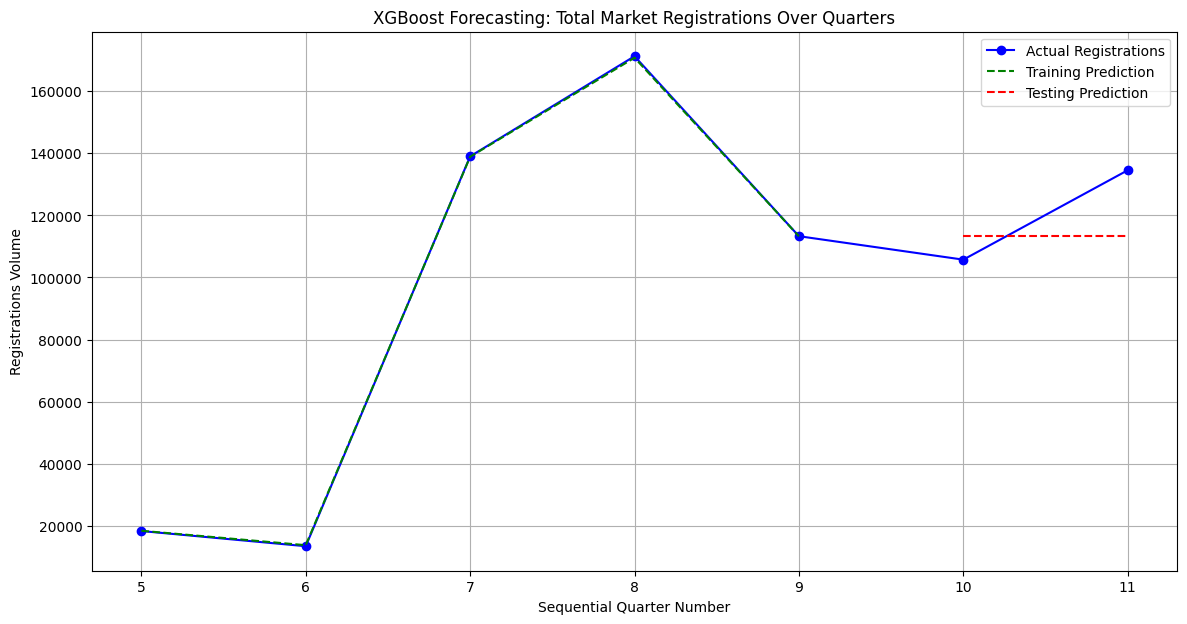

In [37]:

# --- 7. Visualization of Forecast vs. Actual ---

# Reconstruct the full timeline for visualization
full_index = df_tabular['Sequential_Quarter']
train_index = full_index[:len(y_train)]
test_index = full_index[len(y_train):]

plt.figure(figsize=(14, 7))

# Plot Actual Data
plt.plot(full_index, df_tabular['Registrations'], label='Actual Registrations', color='blue', marker='o')

# Plot Training Predictions
plt.plot(train_index, train_predict, label='Training Prediction', color='green', linestyle='--')

# Plot Testing Predictions
plt.plot(test_index, test_predict, label='Testing Prediction', color='red', linestyle='--')

plt.title('XGBoost Forecasting: Total Market Registrations Over Quarters')
plt.xlabel('Sequential Quarter Number')
plt.ylabel('Registrations Volume')
plt.legend()
plt.grid(True)
plt.show()

In [38]:
# --- 8. Model Saving ---

model_filename = '../models/total_market_forecaster_xgb.pkl'

# Save the XGBoost model using pickle
with open(model_filename, 'wb') as file:
    pickle.dump(xgb_model, file)
    
print(f"\nSuccessfully saved the trained XGBoost model to: {model_filename}")


Successfully saved the trained XGBoost model to: total_market_forecaster_xgb.pkl
